# Setting

In [2]:
# %pip install scipy
# %pip install mediapipe
# %pip install opencv-python
# %pip install jupyter
# %pip install pandas
# %pip install numpy
# %pip install matplotlib


import os
import glob
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt

In [3]:
curfolder = os.getcwd()
print(curfolder)

mtfolder = curfolder + '/Output_TimeSeries/'
print(mtfolder)

processedfolder = curfolder + '/TS_processed/'
vidfolder = curfolder + '/Output_Videos/'

# get all the files in the folder
bodyfiles = glob.glob(mtfolder + '*body_world.csv')
handfiles = glob.glob(mtfolder + '*hands_world.csv')
facefiles = glob.glob(mtfolder + '*face_world.csv')

vidfiles = glob.glob(vidfolder + '*.mp4')
print(vidfiles)

e:\VICOM_SignGes_Trajectory
e:\VICOM_SignGes_Trajectory/Output_TimeSeries/
['e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_ACCORDEON_308.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_A-LITTLE_637.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_A-LOT_626.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_AMBULANCE_480.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_ARM_318.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_BABY_008.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_BASKETBALL_011.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_BEARD_331.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_BEER_014.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_BILLIARD_342.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_BIRD_627.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_BIRTH_016.mp4', 'e:\\VICOM_SignGes_Trajectory/Output_Videos\\GtST_DGS_BOOK_348.mp4', '

# Preps

## Clean the data

In [12]:
file = handfiles[0]
# get the last part of the path in sample
def clean_data(file):
    sample = pd.read_csv(file)
    sample
    fileID = os.path.basename(file)
    print(fileID)

    # replace _body.csv with ''
    fileID = fileID.replace('.mp4', '')
    fileID = fileID.replace('.csv', '')
    print(fileID)

    # add fileID column to the sample
    sample['fileID'] = fileID

    # in the sample, get rid of all columns that contain visibility
    visibility_columns = [col for col in sample.columns if 'visibility' in col]

    # get rid of all columns that contain visibility
    sample = sample.drop(visibility_columns, axis=1)

    # for body - lowbody columns
    lowbody = ['FOOT', 'HEEL', 'ANKLE', 'KEE']
    sample = sample.drop([col for col in sample.columns if any(x in col for x in lowbody)], axis=1)


    return sample

sample = clean_data(file)

GtST_DGS_ACCORDEON_308.mp4_hands_world.csv
GtST_DGS_ACCORDEON_308_hands_world


## Flip the Y axis vertical data

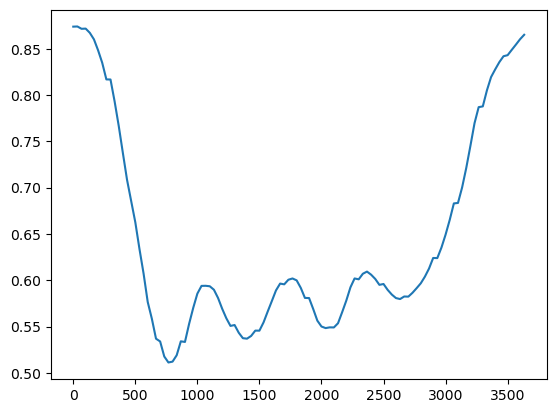

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\2572589367.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[joint][frame] = ytrans
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\2572589367.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[joint][frame] = ytrans
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\2572589367.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[joint][frame] = ytran

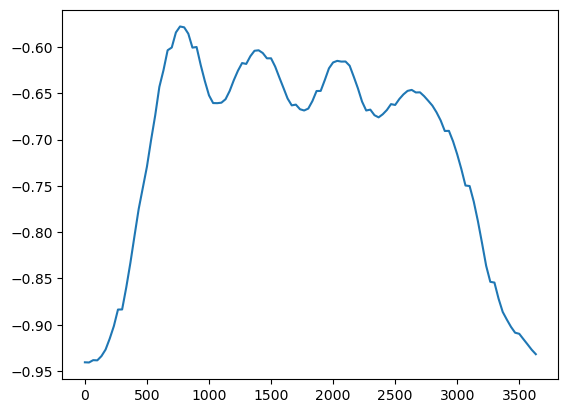

In [13]:
# plot left wrist, vertical (pre flipping)

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

# flip the y-axis data (code modified from envisionbox)
def flip_data(df):
    cols = df.columns
    cols  = [col for col in df.columns if 'Y_' in col]
    cols = list(cols)
        # first get the vertical height of the configuration
        # we only do this for the first frame; the transformation will be applied to all frames
    maxpoint = []
    for joint in cols:
        maxpoint.append(df[joint][0])
        # iterate over each joint, in each frame, to flip the y-axis
    for frame in range(len(df)):
        for joint in cols:
            ytrans = max(maxpoint) - df[joint][frame] - 1
            df[joint][frame] = ytrans
 
    return df

sample = flip_data(sample)

# plot left wrist, vertical (post flipping)

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

## Interpolate the data

In [15]:
# obtain column names
def interpolate(sample):
    cols = sample.columns
    print(cols)

# put away time and fileID from cols
    cols = cols.drop(['time', 'fileID'])

# loop over the cols and interpolate missing data
    for col in cols:
        sample[col] = sample[col].interpolate(method='linear', x = sample['time'], limit=10)
    return cols, sample

cols, sample = interpolate(sample)

Index(['time', 'X_LEFT_WRIST', 'Y_LEFT_WRIST', 'Z_LEFT_WRIST',
       'X_LEFT_THUMB_CMC', 'Y_LEFT_THUMB_CMC', 'Z_LEFT_THUMB_CMC',
       'X_LEFT_THUMB_MCP', 'Y_LEFT_THUMB_MCP', 'Z_LEFT_THUMB_MCP',
       ...
       'X_RIGHT_PINKY_FINGER_PIP', 'Y_RIGHT_PINKY_FINGER_PIP',
       'Z_RIGHT_PINKY_FINGER_PIP', 'X_RIGHT_PINKY_FINGER_DIP',
       'Y_RIGHT_PINKY_FINGER_DIP', 'Z_RIGHT_PINKY_FINGER_DIP',
       'X_RIGHT_PINKY_FINGER_TIP', 'Y_RIGHT_PINKY_FINGER_TIP',
       'Z_RIGHT_PINKY_FINGER_TIP', 'fileID'],
      dtype='object', length=128)


## Smooth the data

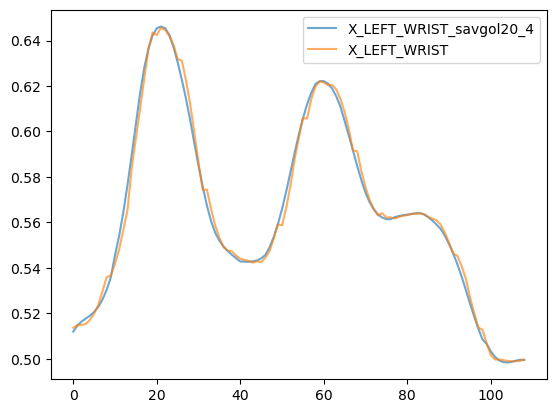

In [124]:
# test the different smoothing filter options - smoothing with savitzky-golay filter
x = 'X_LEFT_WRIST'
z = 'Z_LEFT_WRIST'
y = 'Y_LEFT_WRIST'


# list possible window
window = [20]
# list possible orders
order = [4]

# col of interest
samplecol = [y, z, x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
LKnee_y = sample[y].tolist()
LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
df_smooth[y] = LKnee_y
df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
#plt.xlim(100, 200)
#plt.ylim(.0529,.0535)
plt.show()

# sarka's notes
### 15, 1 seems quite solid

# but for lower body let's try 20,1


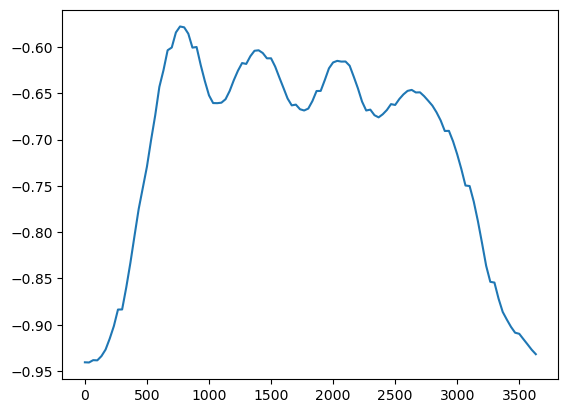

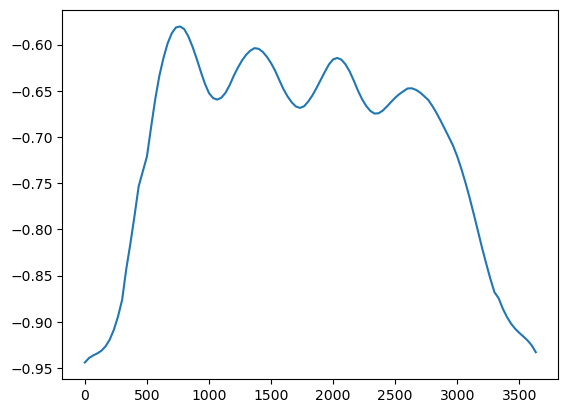

In [16]:
# obtain separate lists of the columns for the upper and lower body (face is included in upper body)

def smooth_data(sample):
    
    if 'body' in sample['fileID'][0]:

        cols_upperbody = ['X_NOSE', 'Y_NOSE', 'Z_NOSE', 'X_LEFT_EYE_INNER', 'Y_LEFT_EYE_INNER', 'Z_LEFT_EYE_INNER', 'X_LEFT_EYE', 'Y_LEFT_EYE', 'Z_LEFT_EYE', 'X_LEFT_EYE_OUTER', 'Y_LEFT_EYE_OUTER', 'Z_LEFT_EYE_OUTER', 'X_RIGHT_EYE_OUTER', 'Y_RIGHT_EYE_OUTER', 'Z_RIGHT_EYE_OUTER', 'X_RIGHT_EYE', 'Y_RIGHT_EYE', 'Z_RIGHT_EYE', 'X_RIGHT_EYE_OUTER.1', 'Y_RIGHT_EYE_OUTER.1', 'Z_RIGHT_EYE_OUTER.1', 'X_LEFT_EAR', 'Y_LEFT_EAR', 'Z_LEFT_EAR', 'X_RIGHT_EAR', 'Y_RIGHT_EAR', 'Z_RIGHT_EAR', 'X_MOUTH_LEFT', 'Y_MOUTH_LEFT', 'Z_MOUTH_LEFT', 'X_MOUTH_RIGHT', 'Y_MOUTH_RIGHT', 'Z_MOUTH_RIGHT', 'X_LEFT_SHOULDER', 'Y_LEFT_SHOULDER', 'Z_LEFT_SHOULDER', 'X_RIGHT_SHOULDER', 'Y_RIGHT_SHOULDER', 'Z_RIGHT_SHOULDER', 'X_LEFT_ELBOW', 'Y_LEFT_ELBOW', 'Z_LEFT_ELBOW', 'X_RIGHT_ELBOW', 'Y_RIGHT_ELBOW', 'Z_RIGHT_ELBOW', 'X_LEFT_WRIST', 'Y_LEFT_WRIST', 'Z_LEFT_WRIST', 'X_RIGHT_WRIST', 'Y_RIGHT_WRIST', 'Z_RIGHT_WRIST', 'X_LEFT_PINKY', 'Y_LEFT_PINKY', 'Z_LEFT_PINKY', 'X_RIGHT_PINKY', 'Y_RIGHT_PINKY', 'Z_RIGHT_PINKY', 'X_LEFT_INDEX', 'Y_LEFT_INDEX', 'Z_LEFT_INDEX', 'X_RIGHT_INDEX', 'Y_RIGHT_INDEX', 'Z_RIGHT_INDEX', 'X_LEFT_THUMB', 'Y_LEFT_THUMB', 'Z_LEFT_THUMB', 'X_RIGHT_THUMB', 'Y_RIGHT_THUMB']
        cols_lowerbody = ['X_LEFT_HIP', 'Y_LEFT_HIP', 'Z_LEFT_HIP', 'X_RIGHT_HIP', 'Y_RIGHT_HIP', 'Z_RIGHT_HIP']

        # smooth upperbody and face with savgol 20,4                            
        for col in cols_upperbody:
            sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
        
        # smooth lowerbod with savgol 30,3
        for col in cols_lowerbody:  
            sample[col] = scipy.signal.savgol_filter(sample[col], 10, 1)

    elif 'hands' in sample['fileID'][0]:
        hand_cols = sample.columns
        # get rid of time and fileID
        hand_cols = hand_cols.drop(['time', 'fileID'])
        # smooth hand with savgol 20,4                                             
        for col in hand_cols:
            sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    
    return(sample)


plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

sample = smooth_data(sample)

# plot the smoothed data
plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()

## Derive Speed and Smooth

In [153]:
# in cols, get rid of Y_. X_, Z_
def derive_speed_smooth(cols, sample):
    # replace Y_ with nothing, but only if there is no string before Y
    speedcols = [col.replace('Y_', '') for col in cols]
    speedcols = [col.replace('PINKF', 'PINKY_F') for col in speedcols]
    speedcols = [col.replace('X_', '') for col in speedcols]
    # replace INDE with INDEX_
    speedcols = [col.replace('INDEF', 'INDEX_F') for col in speedcols]
    speedcols = [col.replace('Z_', '') for col in speedcols]

    print(speedcols)
    # keep only unique values
    speedcols = list(set(speedcols))

    for col in speedcols:
        x = sample['X_' + col]
        y = sample['Y_' + col]
        z = sample['Z_' + col]

        # calculate speed
        sample[col + '_speed'] = np.insert(np.sqrt(np.diff(x) ** 2 + np.diff(y) ** 2 + np.diff(z) ** 2), 0, 0)
        # absolutize
        sample[col + '_speed'] = np.abs(sample[col + '_speed'])
    
    # smooth speed
    for col in speedcols:
        sample[col + '_speed'] = scipy.signal.savgol_filter(sample[col + '_speed'], 20, 4)
    # OR
    #sample[col + '_speed'] = scipy.signal.savgol_filter(sample[col + '_speed'], 30, 3)
    return(sample)


hand_cols = sample.columns
# get rid of time and fileID
hand_cols = hand_cols.drop(['time', 'fileID']) # 'fileID'

#sample = derive_speed_smooth(hand_cols, sample)

# plot RIGHT_WRIST_speed
plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['RIGHT_WRIST_speed'])
plt.show()

['Lwri_sho_x', 'Lwri_sho_y', 'Lwri_sho_z', 'Lwri_sho', 'Rwri_sho_x', 'Rwri_sho_y', 'Rwri_sho_z', 'Rwri_sho', 'Lelb_hip_x', 'Lelb_hip_y', 'Lelb_hip_z', 'Lelb_hip', 'Relb_hip_x', 'Relb_hip_y', 'Relb_hip_z', 'Relb_hip', 'Lkn_elb_x', 'Lkn_elb_y', 'Lkn_elb_z', 'Lkn_elb', 'Rkn_elb_x', 'Rkn_elb_y', 'Rkn_elb_z', 'Rkn_elb', 'Lwri_nose_x', 'Lwri_nose_y', 'Lwri_nose_z', 'Lwri_nose', 'Rwri_nose_x', 'Rwri_nose_y', 'Rwri_nose_z', 'Rwri_nose', 'Lwri_hip_x', 'Lwri_hip_y', 'Lwri_hip_z', 'Lwri_hip', 'Rwri_hip_x', 'Rwri_hip_y', 'Rwri_hip_z', 'Rwri_hip', 'Lwri_sho_speed', 'Lwri_sho_acceleration', 'Lwri_sho_jerk', 'Rwri_sho_speed', 'Rwri_sho_acceleration', 'Rwri_sho_jerk', 'Lelb_hip_speed', 'Lelb_hip_acceleration', 'Lelb_hip_jerk', 'Relb_hip_speed', 'Relb_hip_acceleration', 'Relb_hip_jerk', 'Lkn_elb_speed', 'Lkn_elb_acceleration', 'Lkn_elb_jerk', 'Rkn_elb_speed', 'Rkn_elb_acceleration', 'Rkn_elb_jerk', 'Lwri_nose_speed', 'Lwri_nose_acceleration', 'Lwri_nose_jerk', 'Rwri_nose_speed', 'Rwri_nose_acceleration

KeyError: 'X_Relb_hip_y'

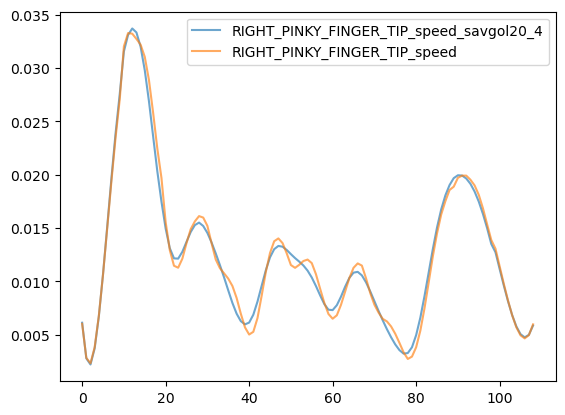

In [127]:
# test smoothing parameters for speed

import scipy
import matplotlib.pyplot as plt
x = 'RIGHT_PINKY_FINGER_TIP_speed'


# list possible window
window = [20]
# list possible orders
order = [4]

# col of interest
samplecol = [x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
#LKnee_y = sample[y].tolist()
#LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
##df_smooth[y] = LKnee_y
#df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
#plt.xlim(100, 200)
plt.show()

## Derive vertical velocity and smooth

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\1902467996.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[col + '_velocity'] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\1902467996.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[col + '_velocity'] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\1902467996.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calli

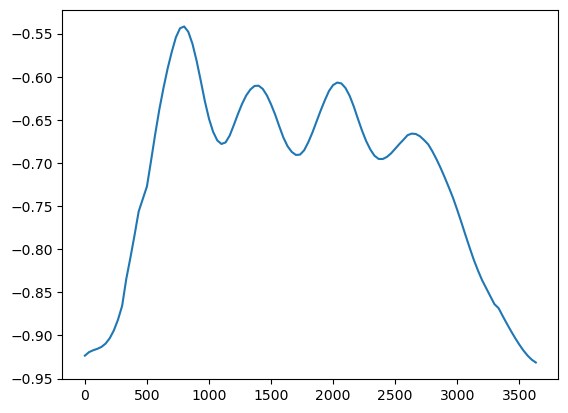

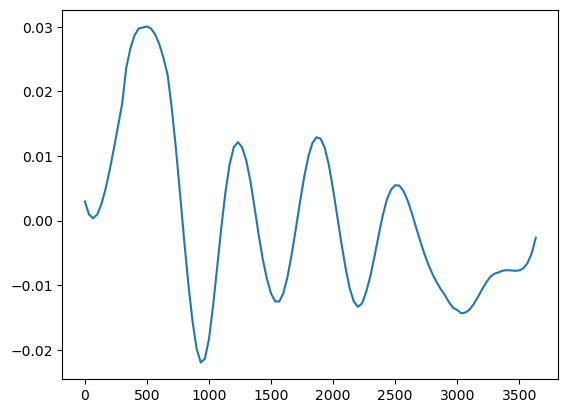

In [18]:
# Get a list of the columns that contain Y_
def derive_vertical_vel_smooth(sample):
    verticalcols = [col for col in sample.columns if 'Y_' in col]
    verticalcols = [col for col in verticalcols if 'speed' not in col] 

# calculate the velocity
    for col in verticalcols:
        sample[col + '_velocity'] = np.insert(np.diff(sample[col]), 0, 0)  
    vel_cols = [col for col in sample.columns if "_velocity" in col]
    for col in vel_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    return sample

sample = derive_vertical_vel_smooth(sample)

plt.plot(sample['time'], sample['Y_RIGHT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['Y_RIGHT_WRIST_velocity'])
plt.show()

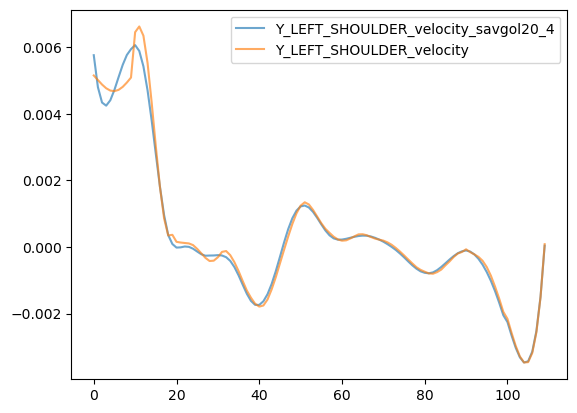

In [24]:
# test possible smoothing windows

import scipy
import matplotlib.pyplot as plt
x = 'Y_LEFT_SHOULDER_velocity'


# list possible window
window = [20]
# list possible orders
order = [4]

# col of interest
samplecol = [x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
#LKnee_y = sample[y].tolist()
#LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
##df_smooth[y] = LKnee_y
#df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
#plt.xlim(100, 200)
plt.show()

## Derive Acceleration and Smooth

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\1318526238.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\1318526238.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\1318526238.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

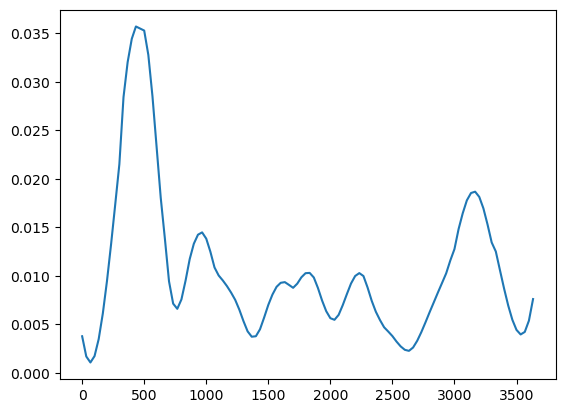

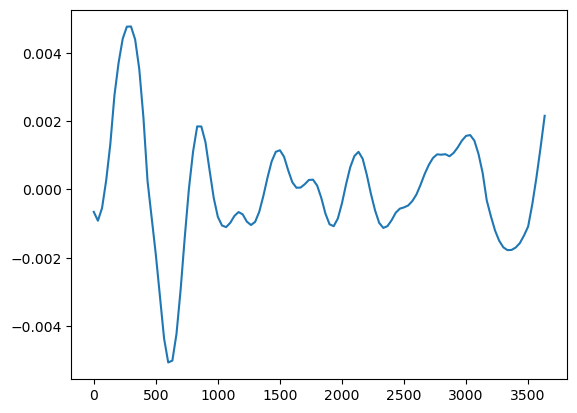

In [19]:
# calculate the acceleration
def derive_accel_smooth(speedcols, sample):
    for col in speedcols:
        newcolname = col.replace('speed', 'acceleration')
        sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0) 
    accel_cols = [col for col in sample.columns if "_acceleration" in col]
    for col in accel_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 10, 3)
    return (sample)

speedcols = [col for col in sample.columns if 'speed' in col]
sample = derive_accel_smooth(speedcols, sample)

plt.plot(sample['time'], sample['LEFT_WRIST_speed'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_acceleration'])
plt.show()
    

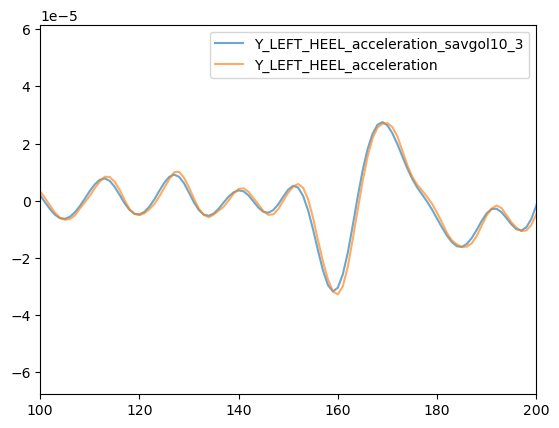

In [14]:
# test possible smoothing windows

import scipy
import matplotlib.pyplot as plt
x = 'Y_LEFT_HEEL_acceleration'


# list possible window
window = [10]
# list possible orders
order = [3]

# col of interest
samplecol = [x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
#LKnee_y = sample[y].tolist()
#LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
##df_smooth[y] = LKnee_y
#df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
plt.xlim(100, 200)
plt.show()

## Derive Jerk and Smooth

C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\3491995224.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\3491995224.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
C:\Users\Sarka Kadava\AppData\Local\Temp\ipykernel_17944\3491995224.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

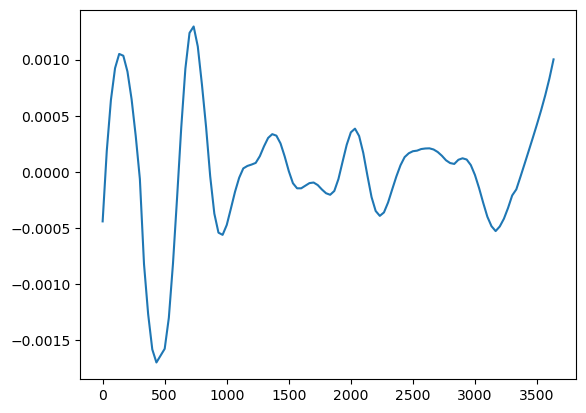

In [20]:
# derive jerk from acceleration 
def derive_jerk_smooth(verticalcols, sample):
    # calcuates the jerk for each vertical column
    for col in accols:
        newcolname = col.replace('acceleration', 'jerk')
        sample[newcolname] = np.insert(np.diff(sample[col]), 0, 0)
    # gets a list of all jerk columns
    jerk_cols = [col for col in sample.columns if "_jerk" in col]
    # smooths all jerk columns
    for col in jerk_cols:
        sample[col] = scipy.signal.savgol_filter(sample[col], 20, 4)
    return (sample)

accols = [col for col in sample.columns if 'acceleration' in col]
sample = derive_jerk_smooth(accols, sample)
plt.plot(sample['time'], sample['LEFT_WRIST_jerk'])
plt.show()


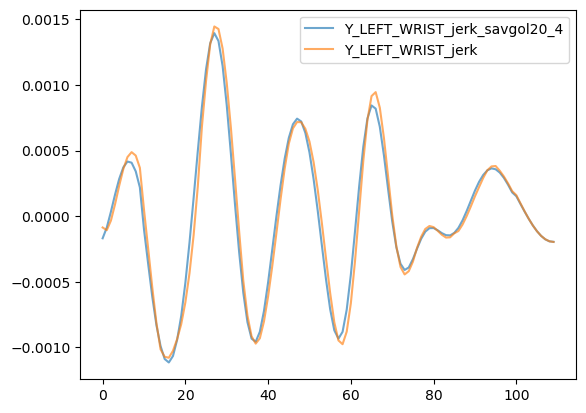

In [29]:
# test possible smoothing windows

import scipy
import matplotlib.pyplot as plt
x = 'Y_LEFT_WRIST_jerk'


# list possible window
window = [20]
# list possible orders
order = [4]

# col of interest
samplecol = [x]

# iterate over handcols and apply all possible combinations of window and order, save it to new df
# prepare new df
df_smooth = pd.DataFrame()

for col in samplecol:
    for win in window:
        for ord in order:
            df_smooth[col + '_savgol' + str(win) + '_' + str(ord)] = scipy.signal.savgol_filter(sample[col], win, ord)


# make R_Hand_x from df_sample a list
LKnee_x = sample[x].tolist()
#LKnee_y = sample[y].tolist()
#LKnee_z = sample[z].tolist()


# load these values into df_smooth as a new column
df_smooth[x] = LKnee_x
##df_smooth[y] = LKnee_y
#df_smooth[z] = LKnee_z

#plot all R_Hand_x columns in one plot
colstoplot = [col for col in df_smooth.columns if x in col]
for col in colstoplot:
    plt.plot(df_smooth[col], label=col, alpha=0.65)
plt.legend()
# make only timewindow 50 to 250
#plt.xlim(100, 200)
plt.show()

## Plotting all the derivations

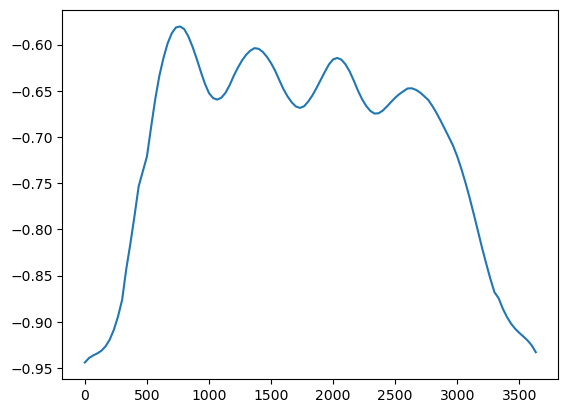

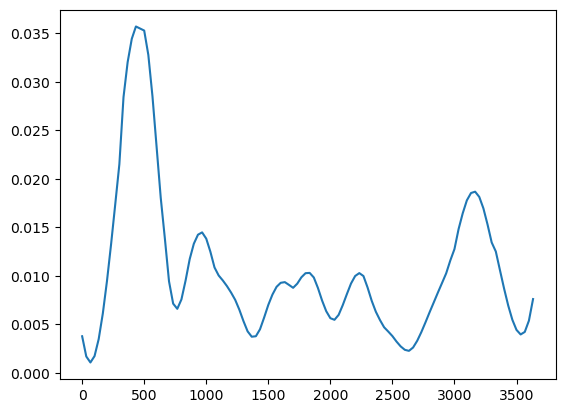

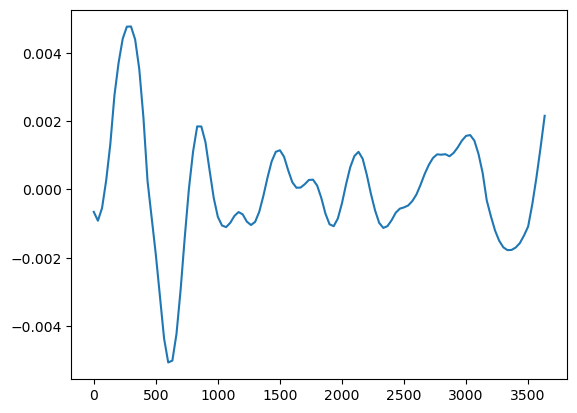

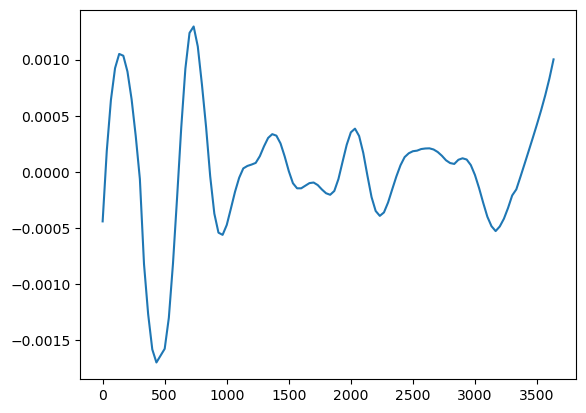

In [21]:

plt.plot(sample['time'], sample['Y_LEFT_WRIST'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_speed'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_acceleration'])
plt.show()
plt.plot(sample['time'], sample['LEFT_WRIST_jerk'])
plt.show()

# Final code to process body and hand file in Output_TimeSeries

In [ ]:
# code to go through every file and recreate a csv with speed, velocity, accerlation, and jerk

import os
import glob
import pandas as pd
import numpy as np

#get the timeseries files
curfolder = os.getcwd()
print(curfolder)

curfolder = os.getcwd()
print(curfolder)

mtfolder = curfolder + '/Output_TimeSeries/'
print(mtfolder)

processedfolder = curfolder + '/TS_processed/'
vidfolder = curfolder + '/Output_Videos/'

# get all the files in the folder
bodyfiles = glob.glob(mtfolder + '*body_world.csv')
handfiles = glob.glob(mtfolder + '*hand_world.csv')
facefiles = glob.glob(mtfolder + '*face_world.csv')

allfiles = bodyfiles + handfiles + facefiles

vidfiles = glob.glob(vidfolder + '*.mp4')
print(vidfiles)

os.makedirs(processedfolder, exist_ok=True)

# for loop to go through every file in the timeseries folder
for file in bodyfiles:
    # get the last part of the path in sample
    sample = clean_data(file)
    sample = flip_data(sample)
    cols, sample = interpolate(sample)
    sample = smooth_data(sample)
    sample = derive_speed_smooth(cols, sample)
    sample = derive_vertical_vel_smooth(sample)
    speedcols = [col for col in sample.columns if 'speed' in col]
    sample = derive_accel_smooth(speedcols, sample)
    accols = [col for col in sample.columns if 'acceleration' in col]
    sample = derive_jerk_smooth(accols, sample)
    fileID = sample['fileID'][0]
    globals()[fileID] = sample
    globals()[fileID].to_csv(os.path.join(processedfolder, f'{fileID}.csv'), index=False)

# for loop to go through every file in the timeseries folder
for file in handfiles:
    # get the last part of the path in sample
    sample = clean_data(file)
    sample = flip_data(sample)
    cols, sample = interpolate(sample)
    sample = smooth_data(sample)
    sample = derive_speed_smooth(cols, sample)
    sample = derive_vertical_vel_smooth(sample)
    speedcols = [col for col in sample.columns if 'speed' in col]   
    sample = derive_accel_smooth(speedcols, sample)
    accols = [col for col in sample.columns if 'acceleration' in col]
    sample = derive_jerk_smooth(accols, sample)
    fileID = sample['fileID'][0]
    globals()[fileID] = sample
    globals()[fileID].to_csv(os.path.join(processedfolder, f'{fileID}.csv'), index=False)



## QUALITY CHECK - the output data in 3d plot

In [52]:
files = glob.glob(processedfolder + '*.csv')

sample = pd.read_csv(files[0])

# get the fileID
fileID = os.path.basename(files[0])

# new name
newname = fileID.replace('body', 'hands')

# find this new file
sample_h = pd.read_csv(os.path.join(processedfolder, newname))

In [34]:
# get rid of all jerk, velocity, and acceleration columns
sample = sample.drop([col for col in sample.columns if 'jerk' in col], axis=1)
sample_h = sample_h.drop([col for col in sample_h.columns if 'jerk' in col], axis=1)
sample = sample.drop([col for col in sample.columns if 'velocity' in col], axis=1)
sample_h = sample_h.drop([col for col in sample_h.columns if 'velocity' in col], axis=1)
sample = sample.drop([col for col in sample.columns if 'acceleration' in col], axis=1)
sample_h = sample_h.drop([col for col in sample_h.columns if 'acceleration' in col], axis=1)
sample = sample.drop([col for col in sample.columns if 'speed' in col], axis=1)
sample_h = sample_h.drop([col for col in sample_h.columns if 'speed' in col], axis=1)


# replace PINKY_F with PINKYF
sample_h.columns = [col.replace('PINKY_F', 'PINKYF') for col in sample_h.columns]
# replace INDEX_F with INDEXF
sample_h.columns = [col.replace('INDEX_F', 'INDEXF') for col in sample_h.columns]

IndexError: single positional indexer is out-of-bounds

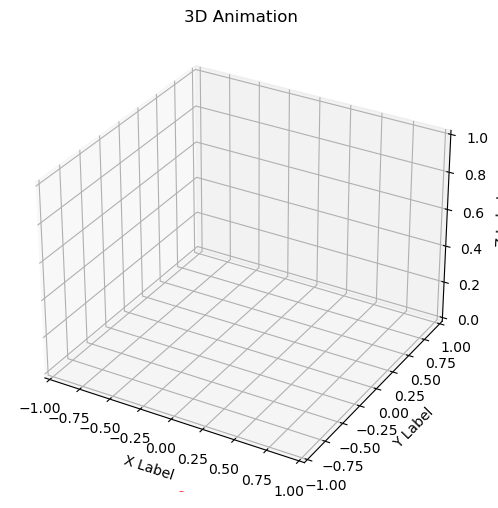

In [45]:
# import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.animation import FuncAnimation

# 3D tracking checking
fileexample = sample
fileexample_hands = sample_h
#print('Well be looking at the following file: ' + fileexample)

MT_tracking = sample
MT_tracking_hands = sample_h

# Create a figure and axis
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# Define the number of frames
num_frames = len(MT_tracking)

# Define the scatter plot
scatter = ax.scatter([], [], [], marker='o')
#scatter2 = ax.scatter([], [], [], marker='o')

# Update function for animation
def update(frame):
    ax.clear()
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label')
    ax.set_zlabel('Z Label')
    ax.set_title('3D Animation')
    
    # Set the limits of the axes based on the maximum values
    ax.set_xlim3d(-1, 1)
    ax.set_ylim3d(-1, 1)
    ax.set_zlim3d(0, 1) #we need to flip the vertical
    
    # Plot the data for the current frame
    frame_data = MT_tracking.iloc[frame]
    frame_data_hands = MT_tracking_hands.iloc[frame]
    x = frame_data.filter(like='X_')
    x_hands = frame_data_hands.filter(like='X_')
    y = frame_data.filter(like='Z_')
    y_hands = frame_data_hands.filter(like='Z_')
    z = frame_data.filter(like='Y_')
    z_hands = frame_data_hands.filter(like='Y_')
    # create scatter that has body in blue, and hands in red
    #scatter = ax.scatter(x, y, z, color='blue')
    scatter = ax.scatter(x_hands, y_hands, z_hands, color='red')

    return scatter

# Create the animation
ani = FuncAnimation(fig, update, frames=num_frames, interval=1000/25)

# display the animation
ani.save('3d_animation.mp4', writer='ffmpeg')


## Joint distances

We will now compute the joint angles, operationalized simply as a distance of the neighboring joints. 

We will look at

In the body model:

wrist-shoulder distance      - as a elbow angle
elbow-hip distance           - as a shoulder angle
fingerknuckle-elbow          - as a wrist angle

Also to get some info about the position of the hand movement, we look at

wrist-nose distance
wrist-hip distance


In [155]:
def getjointdistance(sample, joint1, joint2):

    joint1x = sample['X_' + joint1]
    joint1y = sample['Y_' + joint1]
    joint1z = sample['Z_' + joint1]

    joint2x = sample['X_' + joint2]
    joint2y = sample['Y_' + joint2]
    joint2z = sample['Z_' + joint2]

    # get the x, y, z columns
    x1 = joint1x
    y1 = joint1y
    z1 = joint1z
    x2 = joint2x
    y2 = joint2y
    z2 = joint2z

    # calculate the distance for each dimension separately
    dist_x = x1 - x2
    dist_y = y1 - y2
    dist_z = z1 - z2

    # calculate the total distance
    dist = np.sqrt(dist_x ** 2 + dist_y ** 2 + dist_z ** 2)

    return dist_x, dist_y, dist_z, dist

In [156]:
# for each column that doesn't have _x, _y, _z, calculate speed, acceleration, and jerk

def derive_speed_accel_jerk(df):
    cols = df.columns
    cols = cols.drop(['time', 'fileID'])
    for col in cols:
        if '_x' not in col and '_y' not in col and '_z' not in col:
            # calculate speed
            df[col + '_speed'] = np.insert(np.diff(df[col]), 0, 0)
            # absolutize
            df[col + '_speed'] = np.abs(df[col + '_speed'])
            # smooth it
            df[col + '_speed'] = scipy.signal.savgol_filter(df[col + '_speed'], 15, 3)
            # calculate acceleration
            df[col + '_acceleration'] = np.insert(np.diff(df[col + '_speed']), 0, 0)
            # smooth it
            df[col + '_acceleration'] = scipy.signal.savgol_filter(df[col + '_acceleration'], 15, 3)
            # calculate jerk
            df[col + '_jerk'] = np.insert(np.diff(df[col + '_acceleration']), 0, 0)
            # smooth it
            df[col + '_jerk'] = scipy.signal.savgol_filter(df[col + '_jerk'], 15, 3)
    return df

In [157]:
distances = {}
df_all = pd.DataFrame()
bodyfiles = glob.glob(processedfolder + '*body_world*.csv')

for file in bodyfiles:
    df = pd.read_csv(file)
    fileID = df['fileID'][0]

    # get rid of all speed, velocity, acceleration, and jerk columns
    df = df.drop([col for col in df.columns if 'speed' in col], axis=1)
    df = df.drop([col for col in df.columns if 'velocity' in col], axis=1)
    df = df.drop([col for col in df.columns if 'acceleration' in col], axis=1)
    df = df.drop([col for col in df.columns if 'jerk' in col], axis=1)

    # get left wrist-shoulder distance in each dimension
    Lwri_sho_x, Lwri_sho_y, Lwri_sho_z, Lwri_sho = getjointdistance(df, 'LEFT_WRIST', 'LEFT_SHOULDER')
    # get right wrist-shoulder distance in each dimension
    Rwri_sho_x, Rwri_sho_y, Rwri_sho_z, Rwri_sho = getjointdistance(df, 'RIGHT_WRIST', 'RIGHT_SHOULDER')
    # get left elbow-hip distance in each dimension
    Lelb_hip_x, Lelb_hip_y, Lelb_hip_z, Lelb_hip = getjointdistance(df, 'LEFT_ELBOW', 'LEFT_HIP')
    # get right elbow-hip distance in each dimension
    Relb_hip_x, Relb_hip_y, Relb_hip_z, Relb_hip = getjointdistance(df, 'RIGHT_ELBOW', 'RIGHT_HIP')
    # get leftknuckle-elbow distance in each dimension
    Lkn_elb_x, Lkn_elb_y, Lkn_elb_z, Lkn_elb = getjointdistance(df, 'LEFT_INDEX', 'LEFT_ELBOW')
    # get rightknuckle-elbow distance in each dimension
    Rkn_elb_x, Rkn_elb_y, Rkn_elb_z, Rkn_elb = getjointdistance(df, 'RIGHT_INDEX', 'RIGHT_ELBOW')
    # get left wrist-nose distance in each dimension
    Lwri_nose_x, Lwri_nose_y, Lwri_nose_z, Lwri_nose = getjointdistance(df, 'LEFT_WRIST', 'NOSE')
    # get right wrist-nose distance in each dimension
    Rwri_nose_x, Rwri_nose_y, Rwri_nose_z, Rwri_nose = getjointdistance(df, 'RIGHT_WRIST', 'NOSE')
    # get left wrist-hip distance in each dimension
    Lwri_hip_x, Lwri_hip_y, Lwri_hip_z, Lwri_hip = getjointdistance(df, 'LEFT_WRIST', 'LEFT_HIP')
    # get right wrist-hip distance in each dimension
    Rwri_hip_x, Rwri_hip_y, Rwri_hip_z, Rwri_hip = getjointdistance(df, 'RIGHT_WRIST', 'RIGHT_HIP')
    
    # save all variables into a dictionary
    distances[fileID] = {'Lwri_sho_x': Lwri_sho_x, 'Lwri_sho_y': Lwri_sho_y, 'Lwri_sho_z': Lwri_sho_z, 'Lwri_sho': Lwri_sho, 
                         'Rwri_sho_x': Rwri_sho_x, 'Rwri_sho_y': Rwri_sho_y, 'Rwri_sho_z': Rwri_sho_z, 'Rwri_sho': Rwri_sho,
                         'Lelb_hip_x': Lelb_hip_x, 'Lelb_hip_y': Lelb_hip_y, 'Lelb_hip_z': Lelb_hip_z, 'Lelb_hip': Lelb_hip,
                         'Relb_hip_x': Relb_hip_x, 'Relb_hip_y': Relb_hip_y, 'Relb_hip_z': Relb_hip_z, 'Relb_hip': Relb_hip,
                         'Lkn_elb_x': Lkn_elb_x, 'Lkn_elb_y': Lkn_elb_y, 'Lkn_elb_z': Lkn_elb_z, 'Lkn_elb': Lkn_elb,
                         'Rkn_elb_x': Rkn_elb_x, 'Rkn_elb_y': Rkn_elb_y, 'Rkn_elb_z': Rkn_elb_z, 'Rkn_elb': Rkn_elb,
                         'Lwri_nose_x': Lwri_nose_x, 'Lwri_nose_y': Lwri_nose_y, 'Lwri_nose_z': Lwri_nose_z, 'Lwri_nose': Lwri_nose,
                         'Rwri_nose_x': Rwri_nose_x, 'Rwri_nose_y': Rwri_nose_y, 'Rwri_nose_z': Rwri_nose_z, 'Rwri_nose': Rwri_nose,
                         'Lwri_hip_x': Lwri_hip_x, 'Lwri_hip_y': Lwri_hip_y, 'Lwri_hip_z': Lwri_hip_z, 'Lwri_hip': Lwri_hip, 
                         'Rwri_hip_x': Rwri_hip_x, 'Rwri_hip_y': Rwri_hip_y, 'Rwri_hip_z': Rwri_hip_z, 'Rwri_hip': Rwri_hip}
    
    distances_df = pd.DataFrame(distances[fileID])
    distances_df['time'] = df['time']
    distances_df['fileID'] = fileID

    # absolutize all numerical columns
    for col in distances_df.columns:
        if 'time' not in col and 'fileID' not in col:
            distances_df[col] = np.abs(distances_df[col])

    # derive speed, acceleration, and jerk for all columns
    distances_df = derive_speed_accel_jerk(distances_df)

    df_all = pd.concat([df_all, distances_df])



In [158]:
# save df all
df_all.to_csv(os.path.join(curfolder, 'distances.csv'), index=False)

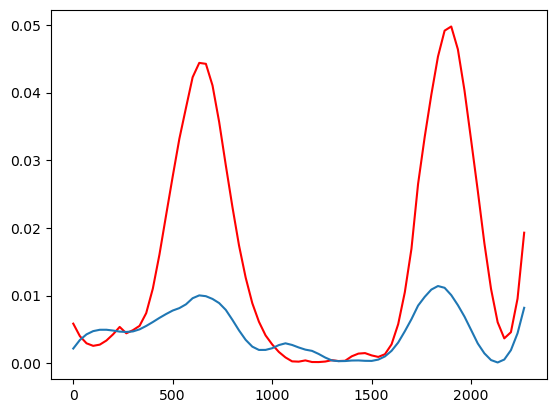

In [159]:
# plot the distance between left wrist and left shoulder

# pick one fileID
sample = distances_df
plt.plot(sample['time'], sample['Rwri_hip_speed'], color='red')
plt.plot(sample['time'], sample['Lwri_hip_speed'])
plt.show()

In [147]:

df_all

,Lwri_sho_x,Lwri_sho_y,Lwri_sho_z,Lwri_sho,Rwri_sho_x,Rwri_sho_y,Rwri_sho_z,Rwri_sho,Lelb_hip_x,Lelb_hip_y,...,Lwri_nose_jerk,Rwri_nose_speed,Rwri_nose_acceleration,Rwri_nose_jerk,Lwri_hip_speed,Lwri_hip_acceleration,Lwri_hip_jerk,Rwri_hip_speed,Rwri_hip_acceleration,Rwri_hip_jerk
0,0.128477,0.457654,0.030962,0.476353,0.084043,0.473987,0.027819,0.482183,0.047354,0.187731,...,0.000673,-0.012767,0.000263,0.000375,0.009963,-0.003895,-0.000603,-0.000260,-0.004605,0.000144
1,0.123821,0.447259,0.060215,0.467972,0.081448,0.457839,0.046212,0.467318,0.040031,0.194979,...,0.000177,-0.011412,0.000739,0.000132,0.001279,-0.004090,0.000260,-0.008329,-0.003139,0.001066
2,0.118092,0.439709,0.079725,0.462218,0.076788,0.446027,0.059844,0.456528,0.039675,0.199740,...,-0.000205,-0.010498,0.000896,-0.000057,-0.004156,-0.003584,0.000887,-0.012259,-0.001539,0.001624
3,0.111916,0.433995,0.092682,0.457675,0.070656,0.437076,0.070790,0.448373,0.044432,0.202833,...,-0.000480,-0.009981,0.000798,-0.000194,-0.006740,-0.002533,0.001301,-0.012690,0.000112,0.001872
4,0.105780,0.429210,0.101854,0.453635,0.063552,0.429688,0.080812,0.441816,0.052667,0.204982,...,-0.000655,-0.009821,0.000511,-0.000282,-0.006867,-0.001092,0.001525,-0.010261,0.001733,0.001861
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,0.111847,0.423466,0.183171,0.474747,0.037528,0.442313,0.106582,0.456518,0.049045,0.234912,...,-0.000110,0.006831,-0.004061,0.000413,-0.001602,-0.000605,0.000734,0.001459,0.008695,-0.000558
65,0.111648,0.424726,0.175851,0.473056,0.034073,0.443186,0.107629,0.457339,0.047628,0.234502,...,-0.000179,0.003921,-0.003241,0.000865,-0.001099,0.000374,0.001008,0.008010,0.007313,-0.001461
66,0.111750,0.425533,0.168203,0.471019,0.034795,0.443155,0.111290,0.458238,0.046144,0.233756,...,-0.000262,0.002315,-0.001923,0.001356,0.000627,0.001620,0.001280,0.012306,0.004970,-0.002428
67,0.112370,0.425560,0.161710,0.468912,0.041195,0.444586,0.115361,0.461153,0.044787,0.232488,...,-0.000357,0.002365,-0.000053,0.001878,0.003794,0.003147,0.001542,0.013698,0.001562,-0.003442
